In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Задание. Агрегатор грузоперевозок

Есть датафрейм *lorry_orders.csv* с информацией о заказах в агрегаторе грузоперевозок:
 - *id_order* - уникальный идентификатор заказа;
 - *dtime_order* - дата+время создания заказа;
 - *dtime_finish* - дата+время окончания заказа (если null, то заказ не был успешно завершён);
 - *weight* - вес перевозимого груза;

С помощью статистических гипотез необходимо ответить на следующие вопросы:

 1. (**3.5 балла**) Найди зависимость конверсии в успешно завершённый заказ от веса :

    **1.1.** (**1.5 балла**)  Построй гистограмму веса и на основании распределения разбей вес на три категории:
     - Тяжёлый;
     - Средний;
     - Лёгкий;

     В качестве пороговых значений используй $33$ и $66$ перцентили распределения.

     Разметь строки в датафрейме названиями этих категорий.
     
     Для разметки можно воспользоваться, например, функцией *where* из *numpy* ([документация](https://numpy.org/doc/2.3/reference/generated/numpy.where.html)).

    **1.2.** (**2 балла**) Сравни с помощью z-теста конверсию в успешно завершённый заказ в трех сегментах;


 2. (**3.5 балла**) Найди зависимость длительности заказа от веса:

    **2.1.** (**1.5 балла**) Построй гистограмму времени заказа (в часах) и на основании распределения разбей время на три категории:
    
     - Долгий;
     - Средний;
     - Быстрый;
     
     В качестве пороговых значений используй $33$ и $66$ перцентили распределения.

     Разметь строки в датафрейме названиями этих категорий.

     Для разметки можно воспользоваться, например, функцией *where* из *numpy* ([документация](https://numpy.org/doc/2.3/reference/generated/numpy.where.html)).

    **2.2.** (**2 балла**) Сравни с помощью z-теста средний вес в трех сегментах


3. (**3 балла**) Конверсия в завершённый заказ, которая была зашита в финансовый план, составляет $71\%$.

    Можно ли утверждать, что наша текущая конверсия соответствует финансовому плану?



Есть датафрейм *lorry_orders.csv* с информацией о заказах в агрегаторе грузоперевозок:
 - *id_order* - уникальный идентификатор заказа;
 - *dtime_order* - дата+время создания заказа;
 - *dtime_finish* - дата+время окончания заказа (если null, то заказ не был успешно завершён);
 - *weight* - вес перевозимого груза;

In [51]:
%pip install openpyxl
%pip install scipy



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 5.9 MB/s  0:00:03m0:00:0100:01

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [30]:
from io import StringIO

raw = pd.read_excel('resources/week6/lorry_orders.xlsx', header=None)
df = pd.read_csv(StringIO('\n'.join(raw.iloc[:, 0])), sep=',')
df.head()

,id_order,dtime_order,dtime_finish,weight
0,1023401,07.9.2025 11:58:48,NaN,395
1,1023403,04.9.2025 23:56:31,13.9.2025 6:25:13,123
2,1023405,06.9.2025 8:10:08,NaN,888
3,1023407,06.9.2025 13:28:43,NaN,740
4,1023409,02.9.2025 8:47:30,15.9.2025 22:27:57,2003


1. (**3.5 балла**) Найди зависимость конверсии в успешно завершённый заказ от веса :

    **1.1.** (**1.5 балла**)  Построй гистограмму веса и на основании распределения разбей вес на три категории:
     - Тяжёлый;
     - Средний;
     - Лёгкий;

     В качестве пороговых значений используй $33$ и $66$ перцентили распределения.

     Разметь строки в датафрейме названиями этих категорий.
     
     Для разметки можно воспользоваться, например, функцией *where* из *numpy* ([документация](https://numpy.org/doc/2.3/reference/generated/numpy.where.html)).

    **1.2.** (**2 балла**) Сравни с помощью z-теста конверсию в успешно завершённый заказ в трех сегментах;

In [52]:
from scipy.stats import norm

def z_test_2side(s1, s2):
  s1_mean = s1.mean()
  s2_mean = s2.mean()
  s1_std = s1.std(ddof=1)
  s2_std = s2.std(ddof=1)
  n1 = len(s1)
  n2 = len(s2)
  z = (s1_mean - s2_mean) / (s1_std**2 / n1 + s2_std**2 / n2)**.5
  pval = 2 * (1-norm.cdf(abs(z)))
  return z, pval


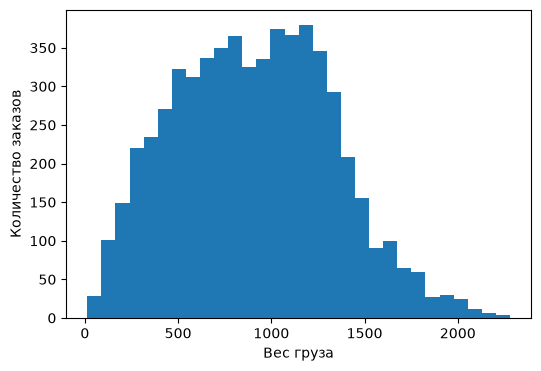

In [70]:
plt.figure(figsize=(6, 4))
plt.hist(df['weight'], bins=30)
plt.xlabel('Вес груза')
plt.ylabel('Количество заказов')
plt.show()

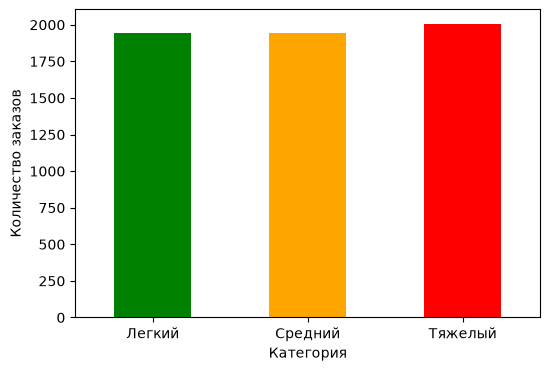

In [32]:
### Твой код здесь
q_66 = np.percentile(df['weight'], 66)
q_33 = np.percentile(df['weight'], 33)
df['weight_categorical'] = np.where(
    df['weight'] <= q_33,
    'Легкий',
    np.where(
        df['weight'] >= q_66,
        'Тяжелый',
        'Средний'
    )
)
plt.figure(figsize=(6, 4))

order = ['Легкий', 'Средний', 'Тяжелый']

df['weight_categorical'].value_counts() \
    .reindex(order) \
    .plot(kind='bar', color=['green', 'orange', 'red'])

plt.xlabel('Категория')
plt.ylabel('Количество заказов')
plt.xticks(rotation=0)
plt.show()


In [34]:
df.head()

,id_order,dtime_order,dtime_finish,weight,weight_categorical
0,1023401,07.9.2025 11:58:48,NaN,395,Легкий
1,1023403,04.9.2025 23:56:31,13.9.2025 6:25:13,123,Легкий
2,1023405,06.9.2025 8:10:08,NaN,888,Средний
3,1023407,06.9.2025 13:28:43,NaN,740,Средний
4,1023409,02.9.2025 8:47:30,15.9.2025 22:27:57,2003,Тяжелый


In [63]:
df['is_finished'] = (~df['dtime_finish'].isnull()).astype(int)
df_gr = df.groupby('weight_categorical', as_index=False).agg({
    'is_finished': 'sum',
    'id_order': 'count'
})
df_gr['conv'] = df_gr['is_finished']/df_gr['id_order']
display(df_gr)

light = df[df['weight_categorical'] == "Легкий"]['is_finished'].values
medium = df[df['weight_categorical'] == "Средний"]['is_finished'].values
hard = df[df['weight_categorical'] == "Тяжелый"]['is_finished'].values

# light.shape, medium.shape, hard.shape
results = [
    ('Легкий — Средний', *z_test_2side(light, medium)),
    ('Легкий — Тяжелый', *z_test_2side(light, hard)),
    ('Средний — Тяжелый', *z_test_2side(medium, hard))
]

results = pd.DataFrame(
    results,
    columns=['Сегменты', 'z_stat', 'p_value']
)

results

,weight_categorical,is_finished,id_order,conv
0,Легкий,1282,1946,0.658787
1,Средний,1344,1945,0.691003
2,Тяжелый,1567,2004,0.781936


,Сегменты,z_stat,p_value
0,Легкий — Средний,-2.145753,3.189268e-02
1,Легкий — Тяжелый,-8.692745,0.000000e+00
2,Средний — Тяжелый,-6.512510,7.390510e-11


In [64]:
alpha = 0.05

results['Вывод'] = np.where(
    results['p_value'] < alpha,
    'Отвергаем H0: конверсии различаются',
    'Не отвергаем H0'
)

results

,Сегменты,z_stat,p_value,Вывод
0,Легкий — Средний,-2.145753,3.189268e-02,Отвергаем H0: конверсии различаются
1,Легкий — Тяжелый,-8.692745,0.000000e+00,Отвергаем H0: конверсии различаются
2,Средний — Тяжелый,-6.512510,7.390510e-11,Отвергаем H0: конверсии различаются


Конверсия увеличивается с ростом весовой категории заказа: для лёгких заказов она составляет 65.88%, для средних — 69.10%, для тяжёлых — 78.19%. Попарный двусторонний z-тест показал статистически значимые различия между конверсиями всех трёх сегментов на уровне значимости 5%.

2. (**3.5 балла**) Найди зависимость длительности заказа от веса:

    **2.1.** (**1.5 балла**) Построй гистограмму времени заказа (в часах) и разбей время на три категории: Долгий, Средний, Быстрый. В качестве пороговых значений используй $33$ и $66$ перцентили распределения.

    **2.2.** (**2 балла**) Сравни с помощью z-теста средний вес в трех сегментах.

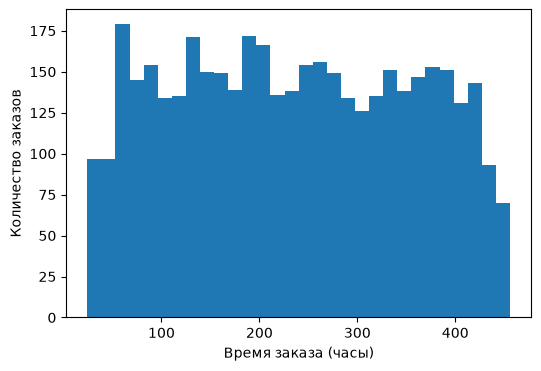

In [65]:
df['dtime_order'] = pd.to_datetime(df['dtime_order'], format='%d.%m.%Y %H:%M:%S')
df['dtime_finish'] = pd.to_datetime(df['dtime_finish'], format='%d.%m.%Y %H:%M:%S')
df['duration'] = (df['dtime_finish'] - df['dtime_order']).dt.total_seconds() / 3600

plt.figure(figsize=(6, 4))
plt.hist(df['duration'].dropna(), bins=30)
plt.xlabel('Время заказа (часы)')
plt.ylabel('Количество заказов')
plt.show()

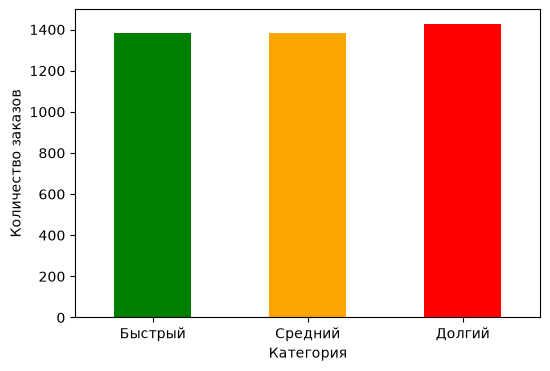

In [66]:
q_66 = np.percentile(df['duration'].dropna(), 66)
q_33 = np.percentile(df['duration'].dropna(), 33)
df['duration_categorical'] = np.where(
    df['duration'].isnull(),
    None,
    np.where(
        df['duration'] <= q_33,
        'Быстрый',
        np.where(
            df['duration'] >= q_66,
            'Долгий',
            'Средний'
        )
    )
)
plt.figure(figsize=(6, 4))

order = ['Быстрый', 'Средний', 'Долгий']

df['duration_categorical'].value_counts() \
    .reindex(order) \
    .plot(kind='bar', color=['green', 'orange', 'red'])

plt.xlabel('Категория')
plt.ylabel('Количество заказов')
plt.xticks(rotation=0)
plt.show()

In [67]:
df.head()

,id_order,dtime_order,dtime_finish,weight,weight_categorical,is_finished,duration,duration_categorical
0,1023401,2025-09-07 11:58:48,NaT,395,Легкий,0,NaN,NaN
1,1023403,2025-09-04 23:56:31,2025-09-13 06:25:13,123,Легкий,1,198.478333,Средний
2,1023405,2025-09-06 08:10:08,NaT,888,Средний,0,NaN,NaN
3,1023407,2025-09-06 13:28:43,NaT,740,Средний,0,NaN,NaN
4,1023409,2025-09-02 08:47:30,2025-09-15 22:27:57,2003,Тяжелый,1,325.674167,Долгий


H0: средний вес в двух сегментах одинаковый. H1: средний вес различается.

In [68]:
df_gr = df.groupby('duration_categorical', as_index=False).agg({
    'weight': 'mean',
    'id_order': 'count'
})
display(df_gr)

fast = df[df['duration_categorical'] == "Быстрый"]['weight'].values
medium = df[df['duration_categorical'] == "Средний"]['weight'].values
slow = df[df['duration_categorical'] == "Долгий"]['weight'].values

results = [
    ('Быстрый — Средний', *z_test_2side(fast, medium)),
    ('Быстрый — Долгий', *z_test_2side(fast, slow)),
    ('Средний — Долгий', *z_test_2side(medium, slow))
]

results = pd.DataFrame(
    results,
    columns=['Сегменты', 'z_stat', 'p_value']
)

results

,duration_categorical,weight,id_order
0,Быстрый,749.404624,1384
1,Долгий,1150.401823,1426
2,Средний,931.450470,1383


,Сегменты,z_stat,p_value
0,Быстрый — Средний,-12.436790,0.0
1,Быстрый — Долгий,-25.968296,0.0
2,Средний — Долгий,-13.643649,0.0


In [69]:
alpha = 0.05

results['Вывод'] = np.where(
    results['p_value'] < alpha,
    'Отвергаем H0: средний вес различается',
    'Не отвергаем H0'
)

results

,Сегменты,z_stat,p_value,Вывод
0,Быстрый — Средний,-12.436790,0.0,Отвергаем H0: средний вес различается
1,Быстрый — Долгий,-25.968296,0.0,Отвергаем H0: средний вес различается
2,Средний — Долгий,-13.643649,0.0,Отвергаем H0: средний вес различается


Средний вес увеличивается с ростом длительности заказа: для быстрых заказов он составляет 749.40, для средних — 931.45, для долгих — 1150.40. Попарный двусторонний z-тест показал статистически значимые различия между средним весом всех трёх сегментов на уровне значимости 5%. Для расчёта длительности использовались только завершённые заказы.

3. (**3 балла**) Конверсия в завершённый заказ, которая была зашита в финансовый план, составляет $71\%$.

Можно ли утверждать, что наша текущая конверсия соответствует финансовому плану?

H0: конверсия равна 71%. H1: конверсия отличается от 71%.

Используем двусторонний z-тест для одной доли на уровне значимости 5%.

In [71]:
p0 = 0.71
conv = df['is_finished'].mean()
n = len(df)

z = (conv - p0) / (p0 * (1 - p0) / n)**.5
pval = 2 * (1 - norm.cdf(abs(z)))

results = pd.DataFrame(
    [(conv, p0, z, pval)],
    columns=['Конверсия', 'План', 'z_stat', 'p_value']
)

results

,Конверсия,План,z_stat,p_value
0,0.711281,0.71,0.216709,0.828435


In [72]:
alpha = 0.05

results['Вывод'] = np.where(
    results['p_value'] < alpha,
    'Отвергаем H0: конверсия отличается от плана',
    'Не отвергаем H0'
)

results

,Конверсия,План,z_stat,p_value,Вывод
0,0.711281,0.71,0.216709,0.828435,Не отвергаем H0


Текущая конверсия составляет 71.13%, плановая — 71%. Двусторонний z-тест дал p-value = 0.828, что больше 0.05. Поэтому H0 не отвергаем: статистически значимых отличий от плановой конверсии не обнаружено. Данные не противоречат финансовому плану, но это не доказывает, что конверсия в точности равна 71%.